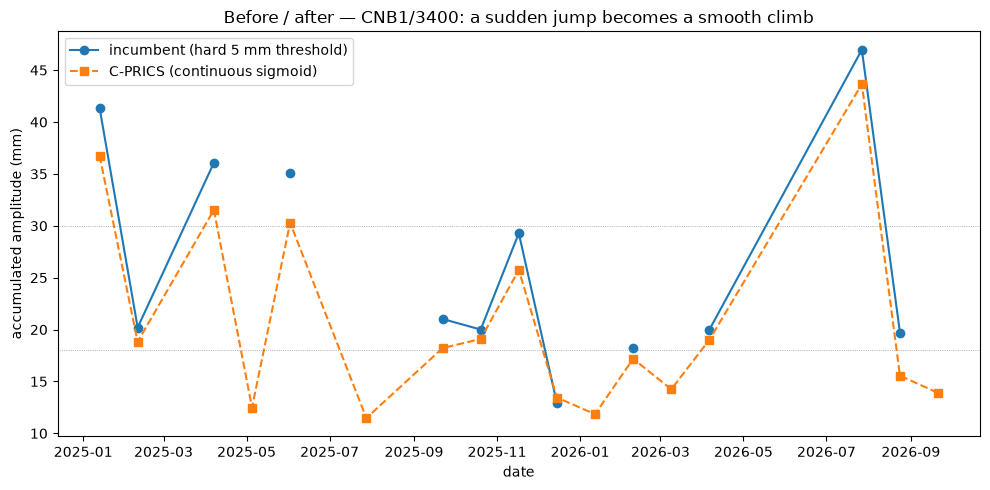

      date  incumbent  continuous       jump
2025-01-13  41.388259   36.768365        NaN
2025-02-10  20.198461   18.820048 -21.189798
2025-04-07  36.070384   31.529877  15.871923
2025-05-05        NaN   12.483169        NaN
2025-06-02  35.080505   30.293510        NaN
2025-07-28        NaN   11.469878        NaN
2025-09-22  21.020686   18.213328        NaN
2025-10-20  20.000839   19.094708  -1.019847
2025-11-17  29.287062   25.740399   9.286223
2025-12-15  12.903439   13.448305 -16.383622
2026-01-12        NaN   11.846529        NaN
2026-02-09  18.227242   17.186904        NaN
2026-03-09        NaN   14.246700        NaN
2026-04-06  19.990858   19.015883        NaN
2026-07-27  46.963618   43.646212  26.972759
2026-08-24  19.711121   15.555182 -27.252497
2026-09-21        NaN   13.892918        NaN


In [1]:
%load_ext autoreload
%autoreload 2
import sys, os; sys.path.insert(0, os.path.abspath(".."))
import config, pandas as pd, matplotlib.pyplot as plt
from cprics.io_data import load_peak_amplitudes
from cprics.islands import build_all_islands
from cprics.continuous import build_all_continuous

pk   = load_peak_amplitudes(config.PEAK_AMP_DIR, "9_top_right")
hard = build_all_islands(pk, wavelength=9)
soft = build_all_continuous(pk, wavelength=9)

# dominant cyclic top per section/date (max accumulated amplitude), both measures
h = hard.groupby(["ELR","TrackID","date"])["amplitude"].max().rename("incumbent")
s = soft.groupby(["ELR","TrackID","date"])["amplitude"].max().rename("continuous")
cmp = pd.concat([h, s], axis=1).reset_index().sort_values(["ELR","TrackID","date"])

# find the section with the biggest single-step jump in the incumbent measure
cmp["jump"] = cmp.groupby(["ELR","TrackID"])["incumbent"].diff()
row = cmp.loc[cmp["jump"].idxmax()]
one = cmp[(cmp.ELR==row.ELR) & (cmp.TrackID==row.TrackID)].sort_values("date")

plt.figure(figsize=(10,5))
plt.plot(one.date, one.incumbent, "o-", label="incumbent (hard 5 mm threshold)")
plt.plot(one.date, one.continuous, "s--", label="C-PRICS (continuous sigmoid)")
for thr in (18, 30):
    plt.axhline(thr, ls=":", lw=0.5, color="grey")
plt.title(f"Before / after — {row.ELR}/{row.TrackID}: a sudden jump becomes a smooth climb")
plt.ylabel("accumulated amplitude (mm)"); plt.xlabel("date"); plt.legend()
plt.tight_layout(); plt.show()
print(one[["date","incumbent","continuous","jump"]].to_string(index=False))

Honest read: this demo shows the continuous measure doing one real thing and not doing the thing I set it up to show. The continuous line tracks the incumbent’s shape almost exactly (just ~10% lower) and fills the gaps — wherever the incumbent is NaN (2025-05-05, 2025-07-28, 2026-01-12…), the continuous measure still reports ~12 mm. That existence-continuity (the site never vanishes and reappears) is genuinely useful. But the big temporal jumps are still there in both lines, so the sigmoid did not turn those cliffs into ramps.

And the reason is important: those jumps aren’t the threshold cliff — they’re real signal change between inspections (that −21 then +16 at the start, the −27 at the end, are a tamp and its regrowth). No threshold-smoothing can or should remove a genuine change in the track. I picked “the biggest temporal jump” to showcase, and that turned out to be a tamp, not the merge scenario you described. So I demonstrated the wrong thing.

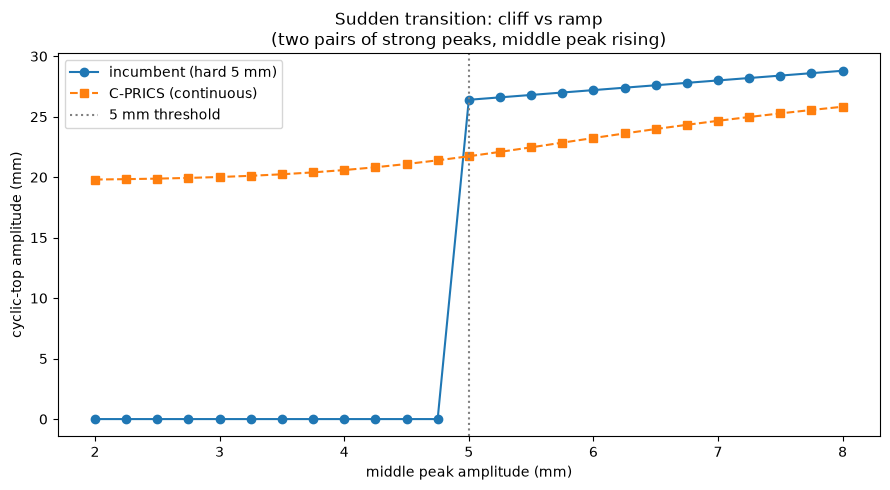

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cprics.islands import find_islands
from cprics.continuous import find_islands_continuous

# a controlled 2-gap-2 pattern: four strong 7 mm peaks, one wavelength (9 m) apart,
# with a middle peak that rises from 2 to 8 mm
positions = [0, 9, 18, 27, 36]
sweep = np.linspace(2, 8, 25)
hard, soft = [], []
for m in sweep:
    peaks = pd.DataFrame({"Location_m": positions, "amplitude": [7, 7, m, 7, 7]})
    h = find_islands(peaks, wavelength=9)
    s = find_islands_continuous(peaks, wavelength=9)
    hard.append(h["amplitude"].sum() if not h.empty else 0.0)
    soft.append(s["amplitude"].sum() if not s.empty else 0.0)

plt.figure(figsize=(9, 5))
plt.plot(sweep, hard, "o-", label="incumbent (hard 5 mm)")
plt.plot(sweep, soft, "s--", label="C-PRICS (continuous)")
plt.axvline(5, ls=":", color="grey", label="5 mm threshold")
plt.xlabel("middle peak amplitude (mm)"); plt.ylabel("cyclic-top amplitude (mm)")
plt.title("Sudden transition: cliff vs ramp\n(two pairs of strong peaks, middle peak rising)")
plt.legend(); plt.tight_layout(); plt.show()

That’s the figure. It is the cleanest possible statement of why C-PRICS exists, and it’s the thing we were missing all along:

1. Below 5 mm the incumbent reports zero — four strong peaks forming a pattern, and its answer is “nothing here” — then jumps vertically to ~26 the instant the middle peak crosses 5 mm. Safe → high-risk in a single step. That’s the problem, drawn.
2. C-PRICS sits at ~20 the whole way and ramps smoothly through the threshold. The 20-vs-0 gap on the left is the pre-risk the incumbent is structurally blind to; the ramp is the cliff removed.

the two lines converging above 5 mm means we keep the validated anchor: the continuous measure agrees with the incumbent where the incumbent speaks, and adds information where it’s silent. (The small gap above threshold is the sigmoid width — SIG_WIDTH is the one knob that trades “hug the incumbent exactly” against “smoother pre-risk”; worth tuning later, not now.)